![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Geometry Operations, Clipping, Spatial Joins and Nearest Neighbours on Millions of Features

Vector data scale differently from rasters. Measuring, buffering or simplifying each feature is
independent work and splits cleanly over cores. Relating features to each other (which county
holds this building, which school is nearest to it) is not: any feature may touch any other, and
a naive comparison of every pair is hopeless for millions of features. This notebook processes the
1.6 million Microsoft building footprints of Kansas with `geolattice.distributed.vector`:
per-feature operations on all cores and the GPU, clipping and spatial joins with partition
pruning, a GPU point-in-polygon join, and nearest-neighbour searches. It ends with 38 million New
York City taxi trips summarized by taxi zone on the CPU and with cuDF on the GPU.

## Overview

### Two kinds of vector work

| Kind | Examples | Parallel pattern |
|---|---|---|
| Per feature | area, length, bounds, centroid, buffer, simplify, reproject, repair | split rows into partitions; no communication |
| Between features | spatial join, clip, overlay, nearest neighbour, weights | find candidate pairs first, then test them exactly |

### Finding candidate pairs

Testing whether two polygons intersect is expensive; testing whether their **bounding boxes**
intersect is four comparisons. Every efficient spatial join therefore works in two steps:

1. **Filter**: a spatial index (an R-tree such as GEOS's STRtree) returns the pairs whose boxes
   overlap.
2. **Refine**: the exact geometric predicate (`intersects`, `within`, ...) runs only on those
   candidates.

When the data are split into partitions, the same idea works one level up: a partition of left
features needs only the right features whose boxes touch the **partition's** bounding box. This
**partition pruning** is effective only when partitions are spatially compact, which is why
GeoLattice sorts features along a Hilbert curve first (notebook 00).

### Shuffles

When both tables are large and partitioned differently, a distributed join must move rows so
that features that might match end up in the same partition: a **shuffle**, the most expensive
step in distributed vector work. GeoLattice avoids it when one side is small enough to send to
every task (counties, zones, facilities), and partitions only the large side. Spark (notebook 10)
and dask-geopandas shuffle both sides when neither is small.

### Points in polygons on a GPU

The most common big join is points in polygons (GPS fixes, building centroids, sensor
locations). Its refine step is the crossing-number test: count how often a ray from the point
crosses the polygon's edges. Every candidate pair is independent, which suits a GPU.

## Vector Processing with GeoLattice

| Function | Returns | GPU |
|---|---|---|
| `pdist.vector.area`, `length`, `bounds` | Series or DataFrame aligned to the input | CuPy kernels, opt-in (`compute="gpu"`) |
| `buffer`, `simplify`, `centroid`, `make_valid`, `to_crs` | the input type with new geometry | CPU only (GEOS, PROJ) |
| `clip(gdf, mask)` | features clipped to the mask | CPU; partitions outside the mask are skipped |
| `sjoin(left, right, predicate=, how=)` | same columns and rows as `geopandas.sjoin` | point-in-polygon on GPU; `engine="sedona"` for Spark |
| `knn(left, right, k=)` | long table of `index_right`, `distance`, `k` | exact brute force in float64 on GPU, opt-in |

GeoPandas input comes back as GeoPandas in the input's row order; dask-geopandas input stays
lazy. Partitions run as Dask tasks on local threads (Shapely 2 releases the GIL) or on the active
cluster.

### Learning objectives

1. Separate per-feature operations from operations between features, and know which parallelize
   trivially.
2. Explain the filter and refine steps, partition pruning and shuffles.
3. Run per-feature operations on 1.6 million buildings on all cores and on the GPU, and check the
   GPU against the CPU.
4. Clip and spatially join with partition pruning and confirm the result equals `geopandas.sjoin`.
5. Run a point-in-polygon join on the GPU and a nearest-neighbour search on CPU and GPU.
6. Aggregate 38 million taxi trips to zones with Dask and with cuDF.

### Data

| Dataset | Content |
|---|---|
| Kansas building footprints | 1.6 million polygons (Microsoft, 2022 release), cached by `dd.kansas_buildings()` |
| Great Plains counties | 225 county polygons, of which 105 in Kansas (EPSG:5070) |
| Wichita schools and hospitals | 183 OpenStreetMap features, cached by `dd.wichita_facilities()` |
| NYC yellow taxi trips 2023 and taxi zones | 38.3 million trips; 263 zone polygons |

### Contents

- Setup
- Reprojecting 1.6 million buildings
- Per-feature measures on CPU and GPU
- Per-feature geometry operations
- Clipping to a county
- Buildings by county: a partitioned spatial join
- Points in polygons on the GPU
- Nearest neighbours
- 38 million taxi trips by zone
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import dask  # Dask configuration


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done


def timed(fn, n=2):  # best wall time of n runs after a warm-up, and the last result
    out = fn(); sync()  # warm-up
    best = np.inf  # best time
    for _ in range(n):  # timed runs
        t = time.perf_counter(); out = fn(); sync(); best = min(best, time.perf_counter() - t)  # one run
    return best, out  # time and result

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## Reprojecting 1.6 million buildings

The footprints come in longitude and latitude (EPSG:4326). Areas and distances need metres, so
the first step reprojects them to the Albers equal-area grid (EPSG:5070) of the Great Plains
rasters. `pdist.vector.to_crs` reprojects partitions in parallel.

In [2]:
b4326 = dd.kansas_buildings()  # 1.6 million polygons, EPSG:4326
print(f"{len(b4326):,} buildings, {int(b4326.geometry.count_coordinates().sum()):,} vertices")  # size
t_gpd, _ = timed(lambda: b4326.to_crs(5070), n=1)  # GeoPandas, one call
t_pd, bld = timed(lambda: pdist.vector.to_crs(b4326, 5070), n=1)  # 24 partitions on 24 threads
print(f"GeoPandas to_crs {t_gpd:.2f} s | pdist.vector.to_crs {t_pd:.2f} s | same result:",  # timings
      bool(bld.geometry.geom_equals_exact(b4326.to_crs(5070).geometry, 1e-6).all()))  # check

1,605,334 buildings, 10,056,309 vertices


GeoPandas to_crs 2.28 s | pdist.vector.to_crs 1.76 s | same result: True


## Per-feature measures on CPU and GPU

Area, perimeter and bounding boxes need only each polygon's own vertices. On the CPU, GEOS
computes them partition by partition on all cores; on the GPU, GeoLattice packs all vertices into
flat CuPy arrays (a "ragged" layout with offsets per polygon) and computes every polygon in one
kernel launch.

In [3]:
rows = []  # timings
for name, fn in [("area", pdist.vector.area), ("length", pdist.vector.length), ("bounds", pdist.vector.bounds)]:  # measures
    t_g, _ = timed(lambda: getattr(bld.geometry, name if name != "bounds" else "bounds"), n=1)  # plain GeoPandas, one core
    t_c, r_c = timed(lambda: fn(bld, compute="cpu"))  # all cores
    t_u, r_u = timed(lambda: fn(bld, compute="gpu")) if caps["gpus"] else (np.nan, r_c)  # GPU
    diff = float(np.nanmax(np.abs(np.asarray(r_u, float) - np.asarray(r_c, float))))  # largest difference
    rows.append({"measure": name, "GeoPandas (s)": t_g, "pdist CPU (s)": t_c, "pdist GPU (s)": t_u, "largest |GPU - CPU|": diff})  # row
pd.DataFrame(rows).set_index("measure").round(4)  # table

,GeoPandas (s),pdist CPU (s),pdist GPU (s),largest |GPU - CPU|
measure,,,,
area,0.0526,0.0282,1.2020,0.0004
length,0.0535,0.0268,1.2243,0.0000
bounds,0.0568,0.0365,1.4107,0.0000


In [4]:
area = pdist.vector.area(bld)  # m2, GPU when available
print(area.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(0).to_string())  # distribution
print(f"total roof area {area.sum() / 1e6:,.0f} km2 ({area.sum() / 213_100e6:.3%} of Kansas)")  # total

count    1605334.0
mean         241.0
std         1016.0
min            6.0
10%           67.0
50%          165.0
90%          344.0
99%         1443.0
max       354681.0
total roof area 387 km2 (0.182% of Kansas)


The GPU and CPU agree to rounding, but the GPU was about forty times **slower**. Each measure is
a few additions per vertex, while packing 1.6 million Shapely polygons into flat coordinate and
offset arrays happens in Python on the CPU and copying them to the device follows; the kernel
itself is a small part of the time. That is why these GPU versions are opt-in:
`compute="auto"` keeps the CPU, and `compute="gpu"` must be asked for. They pay off only when the
geometries are already in a GPU format (for example from cuSpatial or a GeoArrow buffer). Half of Kansas's buildings have less than about 150 m2 of
footprint; the largest are warehouses, factories and grain elevators.

## Per-feature geometry operations

Buffer, simplify, centroid and repair change the geometry and need GEOS, so they run on the CPU.
They still parallelize over partitions.

In [5]:
rows = []  # timings
for name, gp_fn, pd_fn in [  # GeoPandas and GeoLattice versions
        ("buffer 10 m", lambda: bld.buffer(10), lambda: pdist.vector.buffer(bld, 10)),
        ("simplify 2 m", lambda: bld.simplify(2), lambda: pdist.vector.simplify(bld, 2)),
        ("centroid", lambda: bld.centroid, lambda: pdist.vector.centroid(bld)),
        ("make_valid", lambda: bld.make_valid(), lambda: pdist.vector.make_valid(bld))]:
    t_g, _ = timed(gp_fn, n=1)  # GeoPandas on one core
    t_p, _ = timed(pd_fn, n=1)  # partitions on all cores
    rows.append({"operation": name, "GeoPandas (s)": t_g, "pdist, 24 threads (s)": t_p, "speed-up": t_g / t_p})  # row
print("invalid footprints:", int((~bld.is_valid).sum()))  # data quality
pd.DataFrame(rows).set_index("operation").round(2)  # table

invalid footprints: 1


,GeoPandas (s),"pdist, 24 threads (s)",speed-up
operation,,,
buffer 10 m,19.20,2.54,7.56
simplify 2 m,4.25,1.10,3.88
centroid,0.83,0.75,1.10
make_valid,1.95,0.84,2.31


Buffering, the heaviest of the four, gains most from the cores. The cheap operations gain less,
because splitting the frame into partitions and joining the results costs time of its own.

## Clipping to a county

`pdist.vector.clip` partitions the buildings along a Hilbert curve and drops every partition whose
bounding box misses the mask before any clipping is done. Sedgwick County (Wichita) is small
compared with Kansas, so most partitions are dropped.

In [6]:
counties = dd.gp_counties()  # Great Plains counties, EPSG:5070
ks = counties[counties.state == "KS"].reset_index(drop=True)  # the 105 Kansas counties
sedgwick = ks[ks.county.str.startswith("Sedgwick")]  # Sedgwick County
parts = pdist.spatial_partition(bld, 24)  # the partitions clip will use
box = pdist.partition_bounds(parts)  # their bounding boxes
x0, y0, x1, y1 = sedgwick.total_bounds  # the mask's box
kept = int(np.sum(~((box[:, 2] < x0) | (box[:, 0] > x1) | (box[:, 3] < y0) | (box[:, 1] > y1))))  # partitions that touch it
t_g, c_g = timed(lambda: gpd.clip(bld, sedgwick), n=1)  # GeoPandas
t_p, c_p = timed(lambda: pdist.vector.clip(bld, sedgwick), n=1)  # GeoLattice
print(f"partitions touching Sedgwick County: {kept} of 24")  # pruning
print(f"GeoPandas clip {t_g:.2f} s, pdist.vector.clip {t_p:.2f} s; {len(c_p):,} buildings in both: {len(c_g) == len(c_p)}")  # result

partitions touching Sedgwick County: 6 of 24
GeoPandas clip 1.62 s, pdist.vector.clip 1.06 s; 222,582 buildings in both: True


## Buildings by county: a partitioned spatial join

Which county is each building in? `pdist.vector.sjoin` cuts the 1.6 million buildings into
Hilbert-ordered partitions; for each partition, the county polygons whose boxes touch the
partition's box are the only ones sent to its task. The result has the same rows and columns as
`geopandas.sjoin`.

In [7]:
ks_c = ks[["FIPS", "county", "geometry"]]  # county keys and shapes
t_g, j_g = timed(lambda: gpd.sjoin(bld, ks_c, predicate="intersects"), n=1)  # GeoPandas on one core
t_p, j_p = timed(lambda: pdist.vector.sjoin(bld, ks_c, predicate="intersects"), n=1)  # partitioned, 24 threads
same = set(zip(j_g.index, j_g.index_right)) == set(zip(j_p.index, j_p.index_right))  # same building-county pairs
print(f"GeoPandas {t_g:.2f} s | pdist {t_p:.2f} s | {len(j_p):,} building-county pairs | identical: {bool(same)}")  # result
print(f"buildings in two counties (on a boundary): {int(j_p.index.duplicated().sum()):,}")  # boundary cases

GeoPandas 2.01 s | pdist 0.83 s | 1,605,780 building-county pairs | identical: True
buildings in two counties (on a boundary): 446


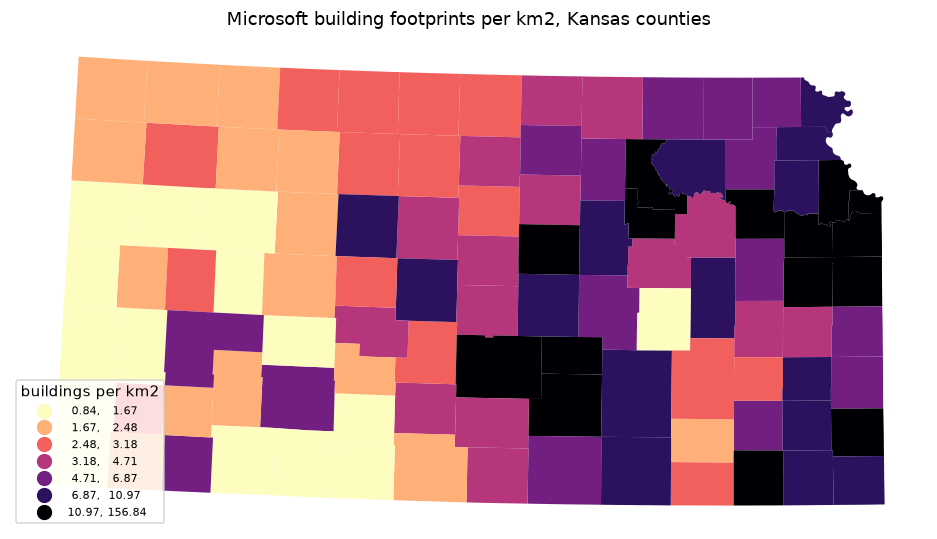

,county,buildings,per_km2
15,Sedgwick County,222582,85.0
76,Johnson County,195082,156.8
96,Shawnee County,83109,57.9
98,Wyandotte County,61582,152.3
95,Douglas County,42029,34.3


In [8]:
per = j_p.groupby("FIPS").size().rename("buildings")  # buildings per county
ks_map = ks.merge(per, on="FIPS", how="left").fillna({"buildings": 0})  # join the counts
ks_map["per_km2"] = ks_map.buildings / (ks_map.area / 1e6)  # density
fig, ax = plt.subplots(figsize=(11, 5))  # one map
ks_map.plot("per_km2", ax=ax, cmap="magma_r", legend=True, scheme="quantiles", k=7,  # quantile classes
            legend_kwds={"title": "buildings per km2", "loc": "lower left", "fontsize": 7})  # legend
ax.set_title("Microsoft building footprints per km2, Kansas counties"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw
ks_map.nlargest(5, "buildings")[["county", "buildings", "per_km2"]].round(1)  # the five largest

Sedgwick, Johnson, Shawnee and Wyandotte counties (Wichita, the Kansas City suburbs and Topeka)
hold the most buildings; the western counties have fewer than ten per square kilometre. The
partitioned join gave exactly the same pairs as GeoPandas, including the buildings that straddle a
county line and so join to two counties.

## Points in polygons on the GPU

Joining building **centroids** instead of polygons turns the question into a point-in-polygon
join, which GeoLattice runs on the GPU: the STRtree supplies candidate pairs and a CUDA kernel
runs the crossing-number test for all of them at once.

In [9]:
pts = bld.set_geometry(bld.geometry.representative_point())  # one point inside each building
rows = {}  # timings
rows["GeoPandas, one core"], r_g = timed(lambda: gpd.sjoin(pts, ks_c, predicate="within"), n=1)  # reference
rows["pdist CPU, 24 threads"], r_c = timed(lambda: pdist.vector.sjoin(pts, ks_c, predicate="within", compute="cpu"))  # CPU
if caps["gpus"]:  # GPU kernel
    rows["pdist GPU"], r_u = timed(lambda: pdist.vector.sjoin(pts, ks_c, predicate="within", compute="gpu"))  # GPU
    print("GPU pairs equal CPU pairs:", bool((r_u.index_right.values == r_c.index_right.values).all() and r_u.index.equals(r_c.index)))  # check
print(f"{len(r_c):,} points matched; unmatched (outside every county): {len(pts) - len(r_c):,}")  # coverage
pd.Series(rows, name="seconds").round(3).to_frame()  # table

GPU pairs equal CPU pairs: True
1,605,334 points matched; unmatched (outside every county): 0


,seconds
"GeoPandas, one core",0.288
"pdist CPU, 24 threads",1.121
pdist GPU,0.746


A point lies in exactly one county, so the 1.6 million points give 1.6 million pairs, identical
on CPU and GPU. The timings hold a surprise: plain GeoPandas on one core was the fastest. Its
bulk `STRtree.query` with a predicate runs entirely in GEOS's C code, and with only 105 polygons
the refine step is cheap. The partitioned join spends more on its own bookkeeping (Hilbert sorting
1.6 million points, 24 tasks, concatenating and restoring the row order) than it saves; the GPU
refine step makes it faster than the partitioned CPU path, but not than GeoPandas. Partitioning
pays off when the refine step is expensive (the polygon join above was more than twice as fast),
when the data do not fit one process, or on a cluster. Measure before assuming that parallel is
faster.

## Nearest neighbours

`pdist.vector.knn` finds the `k` nearest points: a multi-threaded KD-tree on the CPU, an exact
brute-force search in float64 on the GPU (which pays off when the target set is small to
moderate). Two questions for Wichita:

1. Which school is nearest to each of its buildings, and how far is it (straight line)?
2. How far apart are buildings: the distance from each building to its 5 nearest neighbours.

In [10]:
fac = dd.wichita_facilities()  # schools and hospitals, EPSG:5070
schools = fac[fac.amenity == "school"].reset_index(drop=True)  # 171 schools
wich = pts.cx[schools.total_bounds[0] - 2000:schools.total_bounds[2] + 2000,  # buildings around Wichita
              schools.total_bounds[1] - 2000:schools.total_bounds[3] + 2000]  # 2 km margin
print(f"{len(wich):,} buildings and {len(schools)} schools")  # sizes
t_c, nn_c = timed(lambda: pdist.vector.knn(wich, schools, k=1, compute="cpu"))  # KD-tree
t_u, nn_u = timed(lambda: pdist.vector.knn(wich, schools, k=1, compute="gpu")) if caps["gpus"] else (np.nan, nn_c)  # GPU
print(f"nearest school: CPU {t_c:.3f} s, GPU {t_u:.3f} s, same answer: {bool(np.allclose(nn_c.distance, nn_u.distance))}")  # check
print((nn_c.distance / 1000).describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())  # km to the nearest school

183,800 buildings and 171 schools


nearest school: CPU 0.017 s, GPU 0.038 s, same answer: True
count    183800.00
mean          1.22
std           1.21
min           0.00
50%           0.78
90%           2.70
99%           6.36
max          10.60


5 nearest neighbours of 183,800 buildings: CPU 0.10 s, GPU 21.10 s, same distances: True


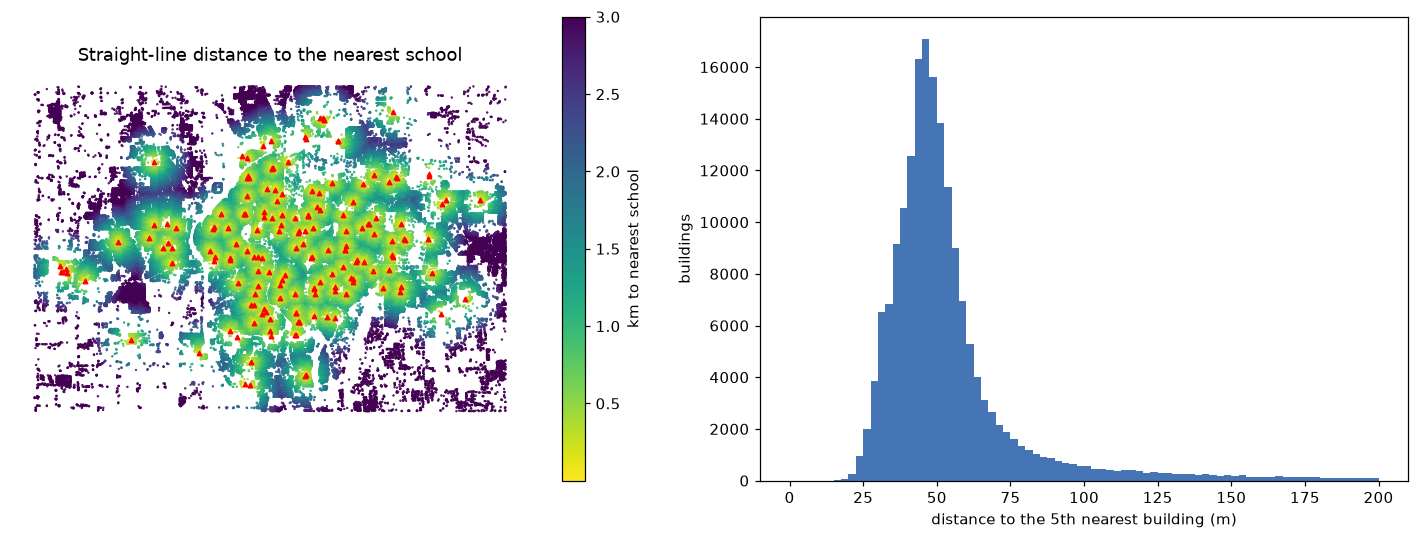

In [11]:
t_c, self_c = timed(lambda: pdist.vector.knn(wich, k=5, compute="cpu"))  # 5 nearest other buildings
t_u, self_u = timed(lambda: pdist.vector.knn(wich, k=5, compute="gpu")) if caps["gpus"] else (np.nan, self_c)  # GPU
print(f"5 nearest neighbours of {len(wich):,} buildings: CPU {t_c:.2f} s, GPU {t_u:.2f} s,",  # timings
      "same distances:", bool(np.allclose(self_c.distance.values, self_u.distance.values)))  # check
fig, ax = plt.subplots(1, 2, figsize=(13, 5))  # two panels
d1 = nn_c.distance / 1000  # km
sc = ax[0].scatter(wich.geometry.x, wich.geometry.y, c=d1.values, s=0.3, cmap="viridis_r", vmax=3)  # buildings coloured by distance
schools.plot(ax=ax[0], color="r", markersize=8, marker="^")  # schools
plt.colorbar(sc, ax=ax[0], label="km to nearest school"); ax[0].set_aspect("equal"); ax[0].set_axis_off()  # labels
ax[0].set_title("Straight-line distance to the nearest school")  # title
ax[1].hist(self_c[self_c.k == 5].distance, bins=np.linspace(0, 200, 81), color="#4575b4")  # distance to the 5th neighbour
ax[1].set_xlabel("distance to the 5th nearest building (m)"); ax[1].set_ylabel("buildings")  # axes
plt.tight_layout(); plt.show()  # draw

With 171 schools as targets both searches take a few hundredths of a second. With 184,000 targets
(the self search) the GPU's brute force compares every pair, about 3 x 10^10 distances, and took
around 200 times longer than the KD-tree, whose search grows only with the logarithm of the
number of targets. GPU knn is therefore opt-in as well. Straight-line distances underestimate travel distance;
notebook 07 measures the same accessibility along the road network.

## 38 million taxi trips by zone

The 2023 taxi records carry the pickup and drop-off **zone ID** rather than coordinates, so the
spatial step is an attribute join between trip counts and the 263 zone polygons. The counting is
the heavy part: 38 million rows. It runs once with Dask on the CPU (one partition per Parquet row
group) and once with cuDF on the GPU.

In [12]:
cols = ["PULocationID", "DOLocationID", "total_amount"]  # the columns needed
trips = dd.taxi_trips(columns=cols)  # lazy Dask DataFrame
t_cpu, pu = timed(lambda: trips.groupby("PULocationID").total_amount.agg(["count", "mean"]).compute(), n=1)  # Dask on CPU
print(f"Dask on CPU: {t_cpu:.2f} s for {int(pu['count'].sum()):,} trips")  # time
if caps["gpus"]:  # GPU dataframe
    from geolattice.distributed._backend import rapids  # imports cuDF without changing CuPy's allocator
    cudf = rapids("cudf")  # GPU DataFrames
    t_read, g = timed(lambda: cudf.read_parquet(dd.TAXI, columns=cols), n=1)  # read straight into GPU memory
    t_gpu, pu_g = timed(lambda: g.groupby("PULocationID").total_amount.agg(["count", "mean"]))  # group on the GPU
    print(f"cuDF: read {t_read:.2f} s, group by zone {t_gpu:.3f} s; same counts:",  # time
          bool((pu_g.to_pandas().sort_index()["count"] == pu.sort_index()["count"]).all()))  # check
    del g  # free GPU memory

Dask on CPU: 0.28 s for 38,310,226 trips


cuDF: read 0.10 s, group by zone 0.025 s; same counts: True


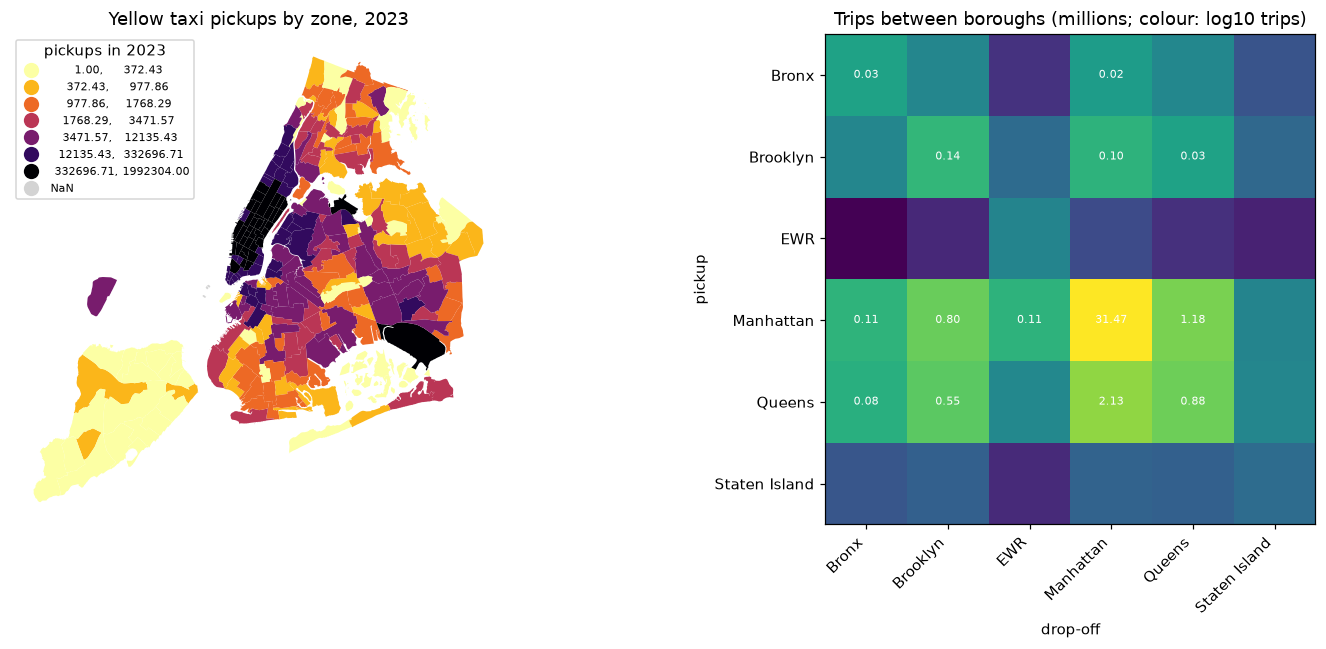

In [13]:
zones = dd.taxi_zones()  # 263 zone polygons
zmap = zones.merge(pu.rename(columns={"count": "pickups", "mean": "mean_fare"}), left_on="LocationID", right_index=True, how="left")  # attribute join
flows = trips.groupby(["PULocationID", "DOLocationID"]).size().compute()  # trips between every pair of zones
boro = zones.set_index("LocationID").borough  # zone -> borough
f = flows.rename("trips").reset_index()  # as a table
f["from"] = f.PULocationID.map(boro); f["to"] = f.DOLocationID.map(boro)  # boroughs
od = f.pivot_table(index="from", columns="to", values="trips", aggfunc="sum").fillna(0) / 1e6  # millions of trips
fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.1, 1]})  # map and matrix
zmap.plot("pickups", ax=ax[0], cmap="inferno_r", legend=True, scheme="quantiles", k=7,  # pickups per zone
          legend_kwds={"title": "pickups in 2023", "fontsize": 7, "loc": "upper left"}, missing_kwds={"color": "lightgrey"})  # legend
ax[0].set_title("Yellow taxi pickups by zone, 2023"); ax[0].set_axis_off()  # title
im = ax[1].imshow(np.log10(od.values * 1e6 + 1), cmap="viridis")  # log scale
ax[1].set_xticks(range(len(od.columns))); ax[1].set_xticklabels(od.columns, rotation=45, ha="right")  # labels
ax[1].set_yticks(range(len(od.index))); ax[1].set_yticklabels(od.index)  # labels
for (i, j), v in np.ndenumerate(od.values):  # annotate
    ax[1].text(j, i, f"{v:.2f}" if v >= 0.01 else "", ha="center", va="center", color="w", fontsize=7)  # millions
ax[1].set_title("Trips between boroughs (millions; colour: log10 trips)"); ax[1].set_xlabel("drop-off"); ax[1].set_ylabel("pickup")  # labels
plt.tight_layout(); plt.show()  # draw

Yellow taxis are a Manhattan service: most trips start and end there, with the airports (JFK and
LaGuardia, in Queens) the main exceptions. Reading the Parquet file straight into GPU memory and
grouping there took about half the Dask time, and the group-by itself only a few hundredths of a
second. For tabular aggregations that fit in GPU memory,
cuDF is the quickest tool on this machine; Dask DataFrames take over when the table does not fit.

## Summary and exercises

- Per-feature operations split over partitions: buffering 1.6 million buildings ran almost eight
  times faster on 24 threads than in plain GeoPandas, simplifying four times; cheap operations
  such as centroids gained little.
- Area, length and bounds also run as CuPy kernels; the GPU matched the CPU to rounding but was
  about forty times slower, because packing the geometries dominates. These GPU versions are
  opt-in.
- Spatial joins filter with bounding boxes and refine exactly. Partition pruning sent each
  Hilbert-ordered partition only the counties near it, and the result equalled `geopandas.sjoin`;
  it halved the time of the polygon join, but plain GeoPandas won the cheap point-in-polygon join.
- The GPU point-in-polygon join and the GPU k-nearest-neighbour search gave the same answers as
  the CPU. Brute-force GPU knn was far slower than the KD-tree for large target sets.
- 38 million taxi trips were grouped by zone with Dask and with cuDF; cuDF took about half the
  time, almost all of it reading the file.

**Exercises**

1. Repeat the county join with `npartitions=6`, 24 and 96. How does the time change, and why?
2. Find the nearest hospital for each Wichita building with `k=3`, and the share of buildings
   more than 5 km from any hospital.
3. Buffer each school by 800 m and count the buildings within walking distance with
   `pdist.vector.sjoin(..., predicate="dwithin", distance=800)` on the school points instead.
   Are the two approaches equivalent?
4. Group the taxi trips by hour of day and pickup borough with cuDF, and plot the daily cycle.